# EDA analysis of training dataset

## Import of main libraries and loading the dataset

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

pd.set_option("display.max_colwidth", 120)

RAW = Path("..") / "data" / "raw"
df = pd.read_csv(RAW / "banking77_train.csv")    # EDA only on train
test = pd.read_csv(RAW / "banking77_test.csv")   # only for a quick sanity check
df.shape, test.shape, df.columns.tolist()

((10003, 2), (3080, 2), ['instruction', 'intent'])

## Basic information about dataset

According to Hugging face information, we have 5 columns with following meanings.

## Dataset

[BANKING77](https://github.com/PolyAI-LDN/task-specific-datasets) (PolyAI, 2020; [paper](https://arxiv.org/abs/2003.04807), CC BY 4.0): 13,083 online-banking customer-service queries labelled with 77 fine-grained intents in a single domain. Official split: 10,003 train / 3,080 test.

It replaces the Bitext dataset used at first: Bitext turned out to be template-based (TF-IDF baseline ≈ 0.99 macro-F1), see `notebooks/00_bitext/`.

### Columns

| Column | Description | Use in this project |
|---|---|---|
| `instruction` | Customer query (`text` in the original files) | Model input |
| `intent` | One of 77 intents, e.g. `card_arrival` (`category` in the original files) | Target |

Two labels are cleaned on download: `Refund_not_showing_up` → `refund_not_showing_up`, `reverted_card_payment?` → `reverted_card_payment`.

### Notes

- **Imbalanced train, balanced test:** 35–187 examples per intent in train, exactly 40 per intent in test. Macro-F1 is the main metric.
- **Short but varied queries:** 11.9 words on average, up to 79.
- **Overlapping intents:** many intents differ only in details, e.g. `top_up_failed` / `top_up_reverted` / `pending_top_up`, `lost_or_stolen_card` / `compromised_card`.
- **Few duplicates:** after normalisation, 30 duplicates and 2 conflicting labels in train, 25 train queries that also appear in test; all are removed.
- **Numbers** (amounts, dates) appear in 2.1% of queries and are normalised to `<num>`.

In [3]:
df.head(10)

,instruction,intent
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived after 2 weeks?,card_arrival
2,I have been waiting over a week. Is the card still coming?,card_arrival
3,Can I track my card while it is in the process of delivery?,card_arrival
4,"How do I know if I will get my card, or if it is lost?",card_arrival
5,When did you send me my new card?,card_arrival
6,Do you have info about the card on delivery?,card_arrival
7,What do I do if I still have not received my new card?,card_arrival
8,Does the package with my card have tracking?,card_arrival
9,I ordered my card but it still isn't here,card_arrival


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10003 entries, 0 to 10002
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   instruction  10003 non-null  str  
 1   intent       10003 non-null  str  
dtypes: str(2)
memory usage: 943.7 KB


We don't have any null values at first glance. We have all columns mentioned in HF

## Intent

Look at intent in train

In [6]:
counts = df["intent"].value_counts()
print(f"intents: {counts.size}, rows: {len(df)}")
print(f"min {counts.min()} ({counts.idxmin()}), max {counts.max()} ({counts.idxmax()}), "
      f"max/min ratio {counts.max() / counts.min():.1f}")
counts.describe()

intents: 77, rows: 10003
min 35 (contactless_not_working), max 187 (card_payment_fee_charged), max/min ratio 5.3


count     77.000000
mean     129.909091
std       32.942207
min       35.000000
25%      112.000000
50%      127.000000
75%      159.000000
max      187.000000
Name: count, dtype: float64

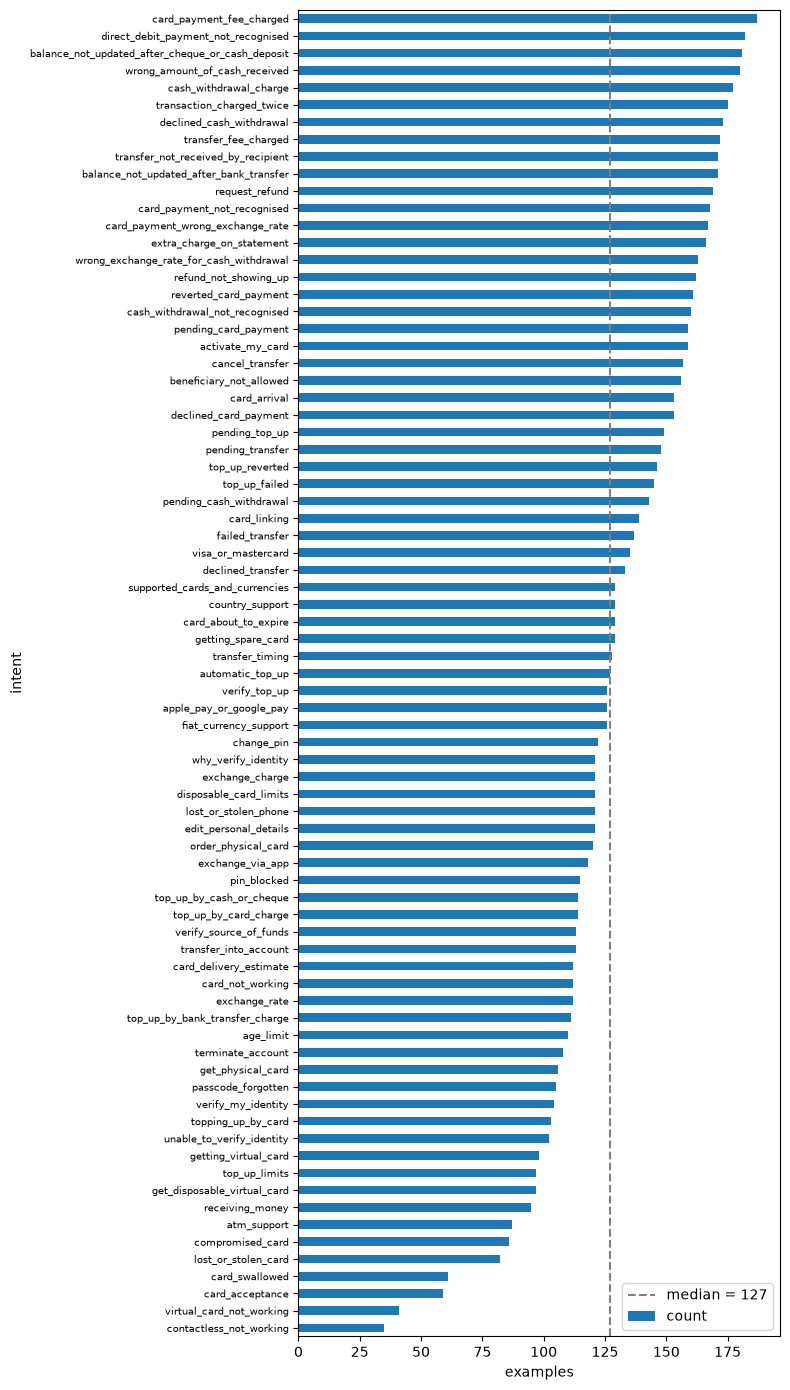

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 14))
counts.sort_values().plot.barh(ax=ax)
ax.axvline(counts.median(), ls="--", c="gray", label=f"median = {counts.median():.0f}")
ax.tick_params(axis="y", labelsize=7)
ax.set_xlabel("examples")
ax.legend()
plt.tight_layout()

The 77 intents are **moderately imbalanced**: from 35 examples (`contactless_not_working`) to 187 (`card_payment_fee_charged`), max/min ≈ 5.3.
The middle half of intents is fairly even (IQR 112–159, median 127), so the imbalance comes from a short tail of small classes,
mostly card-related: `lost_or_stolen_card` (82), `card_swallowed` (61), `card_acceptance` (59), `virtual_card_not_working` (41), `contactless_not_working` (35).

Implications:
- **Macro-F1** is the main metric: it weights every intent equally, so weak small classes are not hidden by large ones.
- All splits are **stratified** to keep these proportions in train / val / batches.
- After the val split and the 40% initial-train cut, the smallest intent has only ~12 examples in the initial train.
- `lost_or_stolen_card` is both a small class and a high-risk intent, so its errors are tracked separately (see critical-error analysis in 02_baseline).

What can we see in test dataset

In [10]:
counts_t = test["intent"].value_counts()
print(f"intents: {counts_t.size}, rows: {len(df)}")
print(f"min {counts_t.min()} ({counts_t.idxmin()}), max {counts_t.max()} ({counts_t.idxmax()}), "
      f"max/min ratio {counts_t.max() / counts_t.min():.1f}")
counts_t.describe()

intents: 77, rows: 10003
min 40 (card_arrival), max 40 (card_arrival), max/min ratio 1.0


count    77.0
mean     40.0
std       0.0
min      40.0
25%      40.0
50%      40.0
75%      40.0
max      40.0
Name: count, dtype: float64

Intents in test dataset are completely balanced

## Texts

Let's see some basic info of the texts.

In [32]:
df["n_words"] = df["instruction"].str.split().str.len()
df["n_words"].describe()

count    10003.000000
mean        11.949415
std          7.891577
min          2.000000
25%          7.000000
50%         10.000000
75%         13.000000
max         79.000000
Name: n_words, dtype: float64

In [33]:
pd.set_option("display.max_colwidth", 200)
print(f"<= 3 words: {(df.n_words <= 3).mean():.1%},  > 30 words: {(df.n_words > 30).mean():.1%}")
display(df.nsmallest(10, "n_words")[["instruction", "intent", "n_words"]])
display(df.nlargest(5, "n_words")[["instruction", "intent", "n_words"]])

<= 3 words: 0.4%,  > 30 words: 4.4%


,instruction,intent,n_words
2187,Cancel Transaction,cancel_transfer,2
4847,passcode retrieval,passcode_forgotten,2
4889,Lost password,passcode_forgotten,2
5176,pending transaction?,pending_card_payment,2
5561,Transfer declined.,declined_transfer,2
9979,Supported countries,country_support,2
791,withdrawal pending meaning?,pending_cash_withdrawal,3
833,Explain pending transactions.,pending_cash_withdrawal,3
1513,Report stolen card,lost_or_stolen_card,3
2077,Cancel a transaction,cancel_transfer,3


,instruction,intent,n_words
3917,"Hearing back from us regarding your important verification results may take 10 minutes to one hour time. If verification results do fail, double-check to make sure all of your images are clear --...",unable_to_verify_identity,79
7310,Hi! I'm a university student studying abroad and I noticed that when I was trying to cross-reference my budget for this month that there were extra fees I was not expecting. Why is that? I've had ...,transfer_fee_charged,78
3934,"Hearing about your verification results from us may take anywhere from 10 minutes to approximately one hour. If this verification has in fact, failed, double-check to make sure that your images a...",unable_to_verify_identity,75
3905,"You will hear back from us about your verification results in 10 minutes to a one hour timeframe. If these verification results do fail, please double-check to make sure your images are clear and...",unable_to_verify_identity,70
3910,It can take between 10 minutes to an hour before you hear back from us about the verification result. Please try again if your verification fails. Make sure you double check that images are clea...,unable_to_verify_identity,70


The most of words has standard lengths for search queries. But we have nearly 4.4% words, that has more than 30 words, that means they contains description of complex problem, and that can be cause of mixing up intents. Some of that appears to us as bank response (instructions contains 'us', 'we'), so its some mistakes, but i notice, that the instructions has 'unable_to_verify_identity'.
 What concerns short instructions, we have some ambigious examples, such as pending_transaction (it can refer to pending_cash_withdrawal, pending_card_payment or other).

In [34]:
agent_voice = df["instruction"].str.contains(
    r"\b(?:from us|you will hear|we will|we'll|hope this helps|let us know)\b", case=False, regex=True)
print(agent_voice.sum())
display(df.loc[agent_voice, ["instruction", "intent", "n_words"]])

5


,instruction,intent,n_words
3905,"You will hear back from us about your verification results in 10 minutes to a one hour timeframe. If these verification results do fail, please double-check to make sure your images are clear and...",unable_to_verify_identity,70
3910,It can take between 10 minutes to an hour before you hear back from us about the verification result. Please try again if your verification fails. Make sure you double check that images are clea...,unable_to_verify_identity,70
3917,"Hearing back from us regarding your important verification results may take 10 minutes to one hour time. If verification results do fail, double-check to make sure all of your images are clear --...",unable_to_verify_identity,79
3932,"If you are waiting for verification, it can take 10 minutes to 60 minutes to get results.You will hear from us once we have it. Please make sure your images are clear and photos of documents are ...",unable_to_verify_identity,64
3934,"Hearing about your verification results from us may take anywhere from 10 minutes to approximately one hour. If this verification has in fact, failed, double-check to make sure that your images a...",unable_to_verify_identity,75


We have only 5 explicit agent answers. Let's have a look at test

In [42]:
agent_voice = test["instruction"].str.contains(
    r"\b(?:from us|you will hear|we will|we'll|hope this helps|let us know)\b", case=False, regex=True)
print(agent_voice.sum())


0


Only zero. That's why it's rational to delete agent answers from train (I experienced some other words that can be used by assistant, but it appers, that clients use that words too. And words above assistant use almost every time to talk with customer on behalf of the bank)

In [36]:
possible_agent_voice_mask = (df['intent'] == 'unable_to_verify_identity')
df[possible_agent_voice_mask].head(10)

,instruction,intent,n_words
3892,Can you help me with proving my identity?,unable_to_verify_identity,8
3893,What proof do you need for my identification?,unable_to_verify_identity,8
3894,Are there any reasons that my identity wouldn't be accepted even though everything I've provided is factual?,unable_to_verify_identity,17
3895,I am having some difficulty verifying my id.,unable_to_verify_identity,8
3896,I am not able to verify my id. Why?,unable_to_verify_identity,9
3897,Help me verify my identify?,unable_to_verify_identity,5
3898,I can't verify identity through the app.,unable_to_verify_identity,7
3899,I need help verifying my identity.,unable_to_verify_identity,6
3900,I'm having trouble proving my identity,unable_to_verify_identity,6
3901,Why isn't my id verified?,unable_to_verify_identity,5


**Bank-voice texts.** A word-boundary search finds 5 texts written from the bank's side ("you will hear back from us…").
All 5 belong to `unable_to_verify_identity` and paraphrase the same reply (verification takes 10–60 minutes, make sure the images are clear).
The other rows of this intent are ordinary customer questions ("I am not able to verify my id. Why?"),
so the intent itself is a customer intent, and these rows are label noise — most likely agent replies that ended up in the dataset.
They are 5 of <N> rows of the intent (~0.05% of train), so we keep them and only document the issue.
They are also the longest texts in the dataset (64–79 words).

In [ ]:
has_ph = df["instruction"].str.contains(r"\{\{.+?\}\}")
print(f"Rows with placeholders: {has_ph.mean():.1%}")

ph = (
    # it allows as to capture placeholders like that:
    # ship {{Order Number}} to {{Delivery City}} -> [Order_Number, Delivery_City]
    df.assign(placeholder=df["instruction"].str.findall(r"\{\{(.+?)\}\}"))
    .explode("placeholder")
    .dropna(subset=["placeholder"])
)
ph["placeholder"].value_counts().head(15)

Rows with placeholders: 24.8%


placeholder
Order Number        2907
Account Type        1011
Person Name          887
Account Category     822
Refund Amount        624
Currency Symbol      372
Delivery City        234
Delivery Country     177
Invoice Number         8
Name: count, dtype: int64

Almost 25 percents of rows has placeholders. The most frequent placeholders are Order Number, Account Type, Person Name, Account Category. Let's see how often all of classes of placeholders consists in any kind of intent.

In [ ]:
ct = pd.crosstab(ph["placeholder"], ph["intent"])
pd.concat(
    [
        (ct.max(axis=1) / ct.sum(axis=1)).rename("top_intent_share"),
        ct.idxmax(axis=1).rename("top_intent"),
        ct.sum(axis=1).rename("rows"),
    ],
    axis=1,
).sort_values("top_intent_share", ascending=False).head(15)

,top_intent_share,top_intent,rows
placeholder,,,
Delivery Country,1.000000,delivery_options,177
Delivery City,1.000000,delivery_options,234
Refund Amount,0.685897,track_refund,624
Invoice Number,0.625000,get_invoice,8
Currency Symbol,0.615591,track_refund,372
Person Name,0.506201,get_invoice,887
Order Number,0.334709,cancel_order,2907
Account Type,0.282888,delete_account,1011
Account Category,0.265207,switch_account,822


24.8% of requests contain template placeholders. Most of them point to a category rather than an intent (e.g. {{Order Number}} is spread across several ORDER intents, top-intent share 0.33). Exceptions: {{Delivery City}} / {{Delivery Country}} appear only in delivery_options (share 1.0, ~400 rows), and refund placeholders mostly in track_refund (~0.65). Real user requests would contain actual values instead of placeholders, so entity normalisation is needed before serving.

In [ ]:
for intent in ["cancel_order", "change_order", "check_invoice", "get_invoice"]:
    print(f"--- {intent}")
    for text in df.loc[df["intent"] == intent, "instruction"].sample(3, random_state=42):
        print("   ", text)

--- cancel_order
    I cannot afford purchase {{Order Number}}
    I have bought some item, I have to cancel order {{Order Number}}
    I do not want this item, cancel order {{Order Number}}
--- change_order
    I have to delete several items from purchase {{Order Number}}
    updating purchase {{Order Number}}
    update purchase00123842
--- check_invoice
    I need assistance to take a quick look at bill #85632
    hepp seeing the bill from {{Person Name}}
    how do I check my bill from {{Person Name}}?
--- get_invoice
    i have got to get bill #37777 how to do it
    i do not know what i need to do to get my invoice #85632
    assistance to get my bills from {{Person Name}}


Entities are anonymised inconsistently: some appear as placeholders ({{Invoice Number}}, 8 rows), others as literal values (#85632, purchase00123842). Both need to be normalised to a single <num> token.

## Flags
Let's analyze how many we have any kind of flags

In [39]:
tags = list("BICNMLPQWKEZ")
pd.Series({t: df["flags"].str.contains(t).mean() for t in tags}, name="share_of_rows").sort_values(ascending=False)

B    1.000000
L    0.897403
Q    0.333730
I    0.291716
Z    0.196710
M    0.183090
C    0.098467
K    0.082874
E    0.070036
P    0.049457
W    0.047931
N    0.017230
Name: share_of_rows, dtype: float64

Every row has tag B and 90% have L, so they are not useful as evaluation slices. The informative slices are Q (colloquial, 33%), Z (typos, 20%) and K (keyword mode, 8%); they are used for slice-level metrics. N (negation, 1.7%) is too small for a stable metric.